# Loop order and the cache

Notebook 03 showed that the C matrix multiplication runs many times faster when two of its loops are swapped, although the arithmetic is identical. Here we measure the effect across matrix sizes and explain it.

In [ ]:
import numpy as np

from compare_efficiency.benchmark import gflops, random_matrices, time_function
from compare_efficiency.c_library import call_c_matmul, compile_c_library, load_c_library

matrix_a, matrix_b = random_matrices(256)
reference_result = matrix_a @ matrix_b

c_library = load_c_library(compile_c_library(["-O3", "-march=native"], "O3"))
c_variants = {"C ijk": c_library.matmul_ijk, "C ikj": c_library.matmul_ikj}
{name: np.allclose(call_c_matmul(function, matrix_a, matrix_b), reference_result) for name, function in c_variants.items()}

{'C ijk': True, 'C ikj': True}

In [ ]:
c_sizes = [64, 128, 256, 512, 1024]
c_seconds = {name: {} for name in c_variants}
for n in c_sizes:
    matrix_a_n, matrix_b_n = random_matrices(n)
    for name, function in c_variants.items():
        c_seconds[name][n] = time_function(lambda: call_c_matmul(function, matrix_a_n, matrix_b_n), repeats=3)

{name: {n: f"{gflops(n, seconds):.2f} GFLOPS" for n, seconds in by_size.items()} for name, by_size in c_seconds.items()}

{'C ijk': {64: '8.48 GFLOPS',
  128: '3.21 GFLOPS',
  256: '2.30 GFLOPS',
  512: '1.57 GFLOPS',
  1024: '0.53 GFLOPS'},
 'C ikj': {64: '18.46 GFLOPS',
  128: '29.64 GFLOPS',
  256: '34.73 GFLOPS',
  512: '32.85 GFLOPS',
  1024: '35.51 GFLOPS'}}

## Loop order and the cache

Now look at the two C versions. They perform exactly the same arithmetic, yet one is far faster than the other, especially for large matrices:

In [ ]:
{n: f"ikj is {c_seconds['C ijk'][n] / c_seconds['C ikj'][n]:.1f}x faster than ijk" for n in c_sizes}

{64: 'ikj is 2.2x faster than ijk',
 128: 'ikj is 9.2x faster than ijk',
 256: 'ikj is 15.1x faster than ijk',
 512: 'ikj is 20.9x faster than ijk',
 1024: 'ikj is 67.4x faster than ijk'}

The reason is memory, not arithmetic. C stores a matrix **row by row**: the whole first row, then the whole second row, and so on, one long line of numbers. This is called *row-major* order. It is like the text of a book, written line after line.

- The `ijk` version's innermost loop moves **down a column** of `B`. In the book analogy, that is reading only the first word of every line: each step jumps a whole row ahead in memory. Every read lands in a different cache line (the deep dive [Numbers and memory](numbers_and_memory.ipynb)), so only one of the eight numbers brought from memory is used.
- The `ikj` version's innermost loop moves **along a row** of `B` and of the result, reading the book line by line. Consecutive numbers share cache lines, the processor can fetch the next lines early, and the compiler can use **SIMD** instructions (*Single Instruction, Multiple Data*), which apply one operation to several numbers at once.

This is the shuffled-versus-in-order experiment of the deep dive [Numbers and memory](numbers_and_memory.ipynb) again, now inside a real algorithm. The advantage grows with $n$: small matrices fit entirely in the cache, so the wasted cache lines hardly matter.

On logarithmic axes, time grows along a straight line for both versions, but the gap between them widens as $n$ grows:

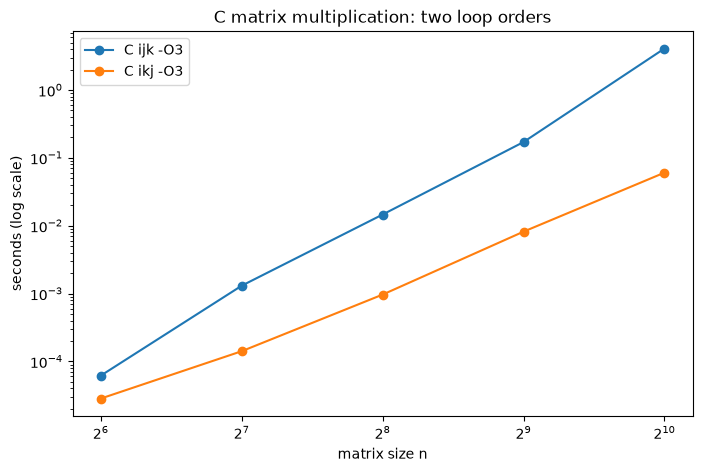

In [ ]:
import matplotlib.pyplot as plt

figure, axis = plt.subplots(figsize=(8, 5))
for name, seconds in c_seconds.items():
    axis.plot(c_sizes, list(seconds.values()), marker="o", label=f"{name} -O3")
axis.set_xscale("log", base=2)
axis.set_yscale("log")
axis.set_xlabel("matrix size n")
axis.set_ylabel("seconds (log scale)")
axis.set_title("C matrix multiplication: two loop orders")
axis.legend()
plt.show()

## What the compiler contributes

So far C was compiled with `-O3 -march=native`. Compiling the same file with `-O0` (no optimisation, a literal translation of the source) shows how much of C's speed comes from the compiler:

In [ ]:
unoptimised_library = load_c_library(compile_c_library(["-O0"], "O0"))
large_a, large_b = random_matrices(1024)
flag_comparison = {}
for flags, library in {"-O0": unoptimised_library, "-O3": c_library}.items():
    for loop_order in ("ijk", "ikj"):
        function = getattr(library, f"matmul_{loop_order}")
        seconds = time_function(lambda: call_c_matmul(function, large_a, large_b), repeats=1)
        flag_comparison[f"C {loop_order} {flags}"] = f"{gflops(1024, seconds):.2f} GFLOPS"
flag_comparison

{'C ijk -O0': '0.62 GFLOPS',
 'C ikj -O0': '1.88 GFLOPS',
 'C ijk -O3': '0.51 GFLOPS',
 'C ikj -O3': '36.33 GFLOPS'}

Typically, `ikj -O0` (good loop order, no optimisation) beats `ijk -O3` (bad loop order, full optimisation). Compiler flags improve the *instructions*; they rarely fix a poor *memory-access pattern*. The optimiser gives a large boost only once the memory access is good, because only then can it use SIMD.

## Why n = 1024 is especially bad for ijk

Caches are not one big pool: each memory address can only be stored in a small group of slots, chosen from some bits of the address. At $n = 1024$, one step down a column jumps $1024 \times 8 = 8192$ bytes, a power of two. Addresses that far apart map to the **same** group of slots, so the column values keep evicting one another from the cache (**cache-set conflicts**). With a size such as 1000, the same loop suffers less. The `ijk` version at two nearby sizes:

In [ ]:
conflict_comparison = {}
for n in (1000, 1024):
    matrix_a_n, matrix_b_n = random_matrices(n)
    seconds = time_function(lambda: call_c_matmul(c_library.matmul_ijk, matrix_a_n, matrix_b_n), repeats=1)
    conflict_comparison[n] = f"{gflops(n, seconds):.2f} GFLOPS"
conflict_comparison

{1000: '4.76 GFLOPS', 1024: '0.52 GFLOPS'}

## Key ideas

- C stores matrices row by row; reading along a row uses whole **cache lines**, reading down a column wastes them.
- The same arithmetic can run tens of times faster just by reordering loops, and the gap grows with the matrix size.
- Compiler optimisation improves instructions but rarely fixes a poor memory-access pattern.
- Sizes that are powers of two can cause **cache-set conflicts**, making the bad loop order even worse.